# DB-scan 


In [72]:
import profile
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import sys
import os
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from scipy.spatial.distance import pdist, squareform
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score,davies_bouldin_score

sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '../..')))

from src.utils import data_understanding as du
from src.utils import utils as ut
profile_df = pd.read_csv("../../data/profiles/patient_profile.csv")

profile_df.drop_duplicates(inplace=True)


profile_df

,subject_id,number_of_hadm,gender,age,lab_event_count,microbio_test_count,unique_microorganisms_count,unique_antibiotics_count,unique_procedures_count,max_glucose,abnormal_lab_event_ratio,resistant_microorganism_ratio,intermediate_microorganism_ratio,sensitive_microorganism_ratio,icd_binary_scaled
0,10000980,2,1,75.0,169.0,1.0,0.0,0.0,7.0,163.0,0.408284,0.0,0.0,0.0,0.666669
1,10002013,1,1,69.0,40.0,0.0,0.0,0.0,2.0,300.0,0.375000,0.0,0.0,0.0,0.000001
2,10002155,1,1,69.0,276.0,4.0,0.0,0.0,8.0,140.0,0.384058,0.0,0.0,0.0,0.000001
3,10004457,1,0,66.0,21.0,0.0,0.0,0.0,0.0,92.0,0.285714,0.0,0.0,0.0,0.000650
4,10007058,1,0,48.0,112.0,2.0,0.0,0.0,2.0,111.0,0.375000,0.0,0.0,0.0,0.000001
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4378,19998596,1,1,71.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.166666
4379,19998597,1,1,57.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.000080
4380,19998598,1,1,69.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.083332
4381,19998599,1,0,59.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.000039


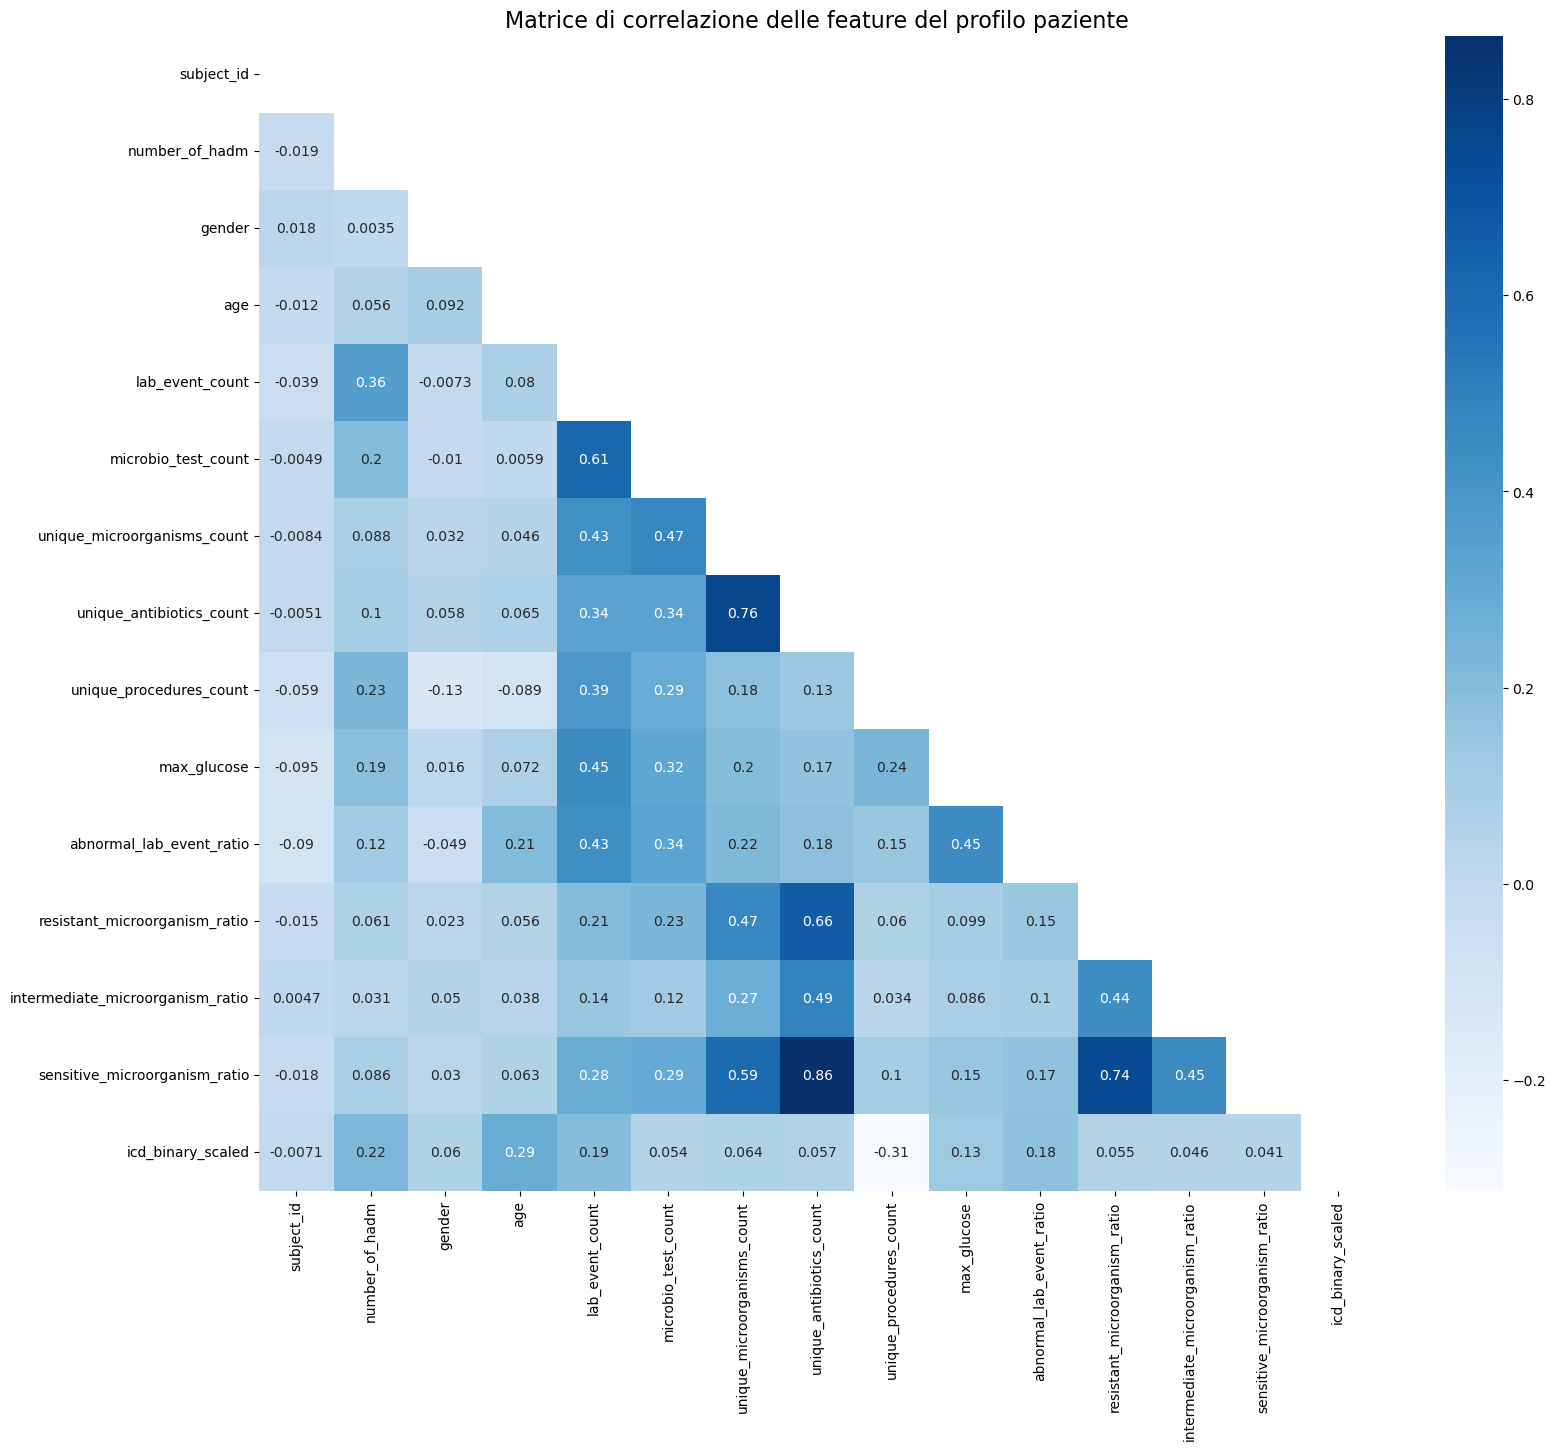

In [73]:
#correletion
# Seleziona solo le colonne numeriche dal profilo paziente
numeric_cols = profile_df.select_dtypes(include='number').columns
profile_num= profile_df[numeric_cols]

# Calcola la matrice di correlazione
corr_matrix = profile_num.corr()

# Maschera triangolare superiore
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

# Plot
plt.figure(figsize=(18,15))
sns.heatmap(corr_matrix, annot=True, cmap='Blues', mask=mask)
plt.title("Matrice di correlazione delle feature del profilo paziente", fontsize=16)
plt.show()

## some consideration
### sensitve_micro_ratio and unique-antibioti_count have a correlation>0.8 , for our analysis sensitve_micro_ratio is more signficant, I drop the other

In [74]:
#Convert subject_id to string
profile_df=profile_df.drop(columns=['gender','unique_antibiotics_count'])
profile_df['subject_id'] = profile_df['subject_id'].astype(str)
# Scale with min-max scaler, but not icd_binary_scaled
numeric_cols = profile_df.select_dtypes(include=['float64', 'int64']).columns.tolist()
numeric_cols.remove('icd_binary_scaled') # Exclude icd_binary_scaled since it's already scaled
#remoive columns with more than 0.8 of correlation



In [75]:
scaler = MinMaxScaler()
X = scaler.fit_transform(profile_df[numeric_cols].values)

# Re adding icd_binary_scaled to X
X = np.hstack((X, profile_df[['icd_binary_scaled']].values))

In [76]:
#compute pairwise distance and distance matrix
dist = pdist(X, 'euclidean') #pair wise distance
print (dist)
dist = squareform(dist) #distance matrix given the vector dist
print()
print(dist)

[0.87083761 0.75043119 0.82890443 ... 0.15428523 0.1997354  0.31168891]

[[0.         0.87083761 0.75043119 ... 0.97271604 1.0427825  1.02674182]
 [0.87083761 0.         0.63916855 ... 1.0307688  1.03557063 1.04335926]
 [0.75043119 0.63916855 0.         ... 0.74800545 0.75460875 0.7652623 ]
 ...
 [0.97271604 1.0307688  0.74800545 ... 0.         0.15428523 0.1997354 ]
 [1.0427825  1.03557063 0.75460875 ... 0.15428523 0.         0.31168891]
 [1.02674182 1.04335926 0.7652623  ... 0.1997354  0.31168891 0.        ]]


## strategia 
### parto da min-sample 5, guardo il gomito e metto eps=0.3 : troppi cluster allora umento min_sample 
### con 8 min sapmle ancora troppi cluster
### provo 10 non va ancora 
### arrivata a 15 ho meno cluster ma anche con la scelta igliore di eps, troppo sbilanciati, aumenta ancora min_sample

In [173]:
k = 5
kth_distances = list()
for d in dist:
    index_kth_distance = np.argsort(d)[k]
    kth_distances.append(d[index_kth_distance])

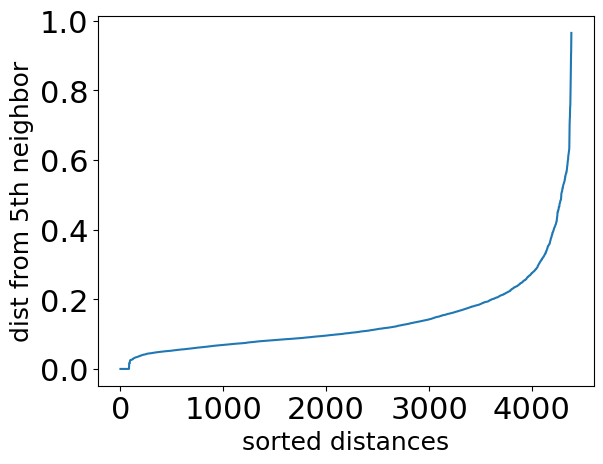

In [174]:
#plot the sorted kth distances
plt.plot(range(0, len(kth_distances)), sorted(kth_distances))
plt.ylabel('dist from %sth neighbor' % k, fontsize=18)
plt.xlabel('sorted distances', fontsize=18)
plt.tick_params(axis='both', which='major', labelsize=22)
plt.show()

In [175]:
# Funzione aggiornata per calcolare solo il Silhouette Score
epsList = [ 0.2, 0.3, 0.4]
best_ms, best_eps, best_silhouette = 0, 0, -1.0

for min_samples in range(5, 30):
    for eps in epsList:
        dbscan = DBSCAN(eps=eps, min_samples=min_samples)
        dbscan.fit(X)
        
        # Ottieni i cluster generati
        unique_labels, counts = np.unique(dbscan.labels_, return_counts=True)
        clusters = len(unique_labels)
        
        # Verifica il numero di cluster (escludendo noise se presente)
        if clusters > 1:
            silhouette = silhouette_score(X, dbscan.labels_)
            print(f'min_samples: {min_samples}, eps: {eps}, Silhouette Score: {silhouette:.4f}')
            
            # Aggiorna il miglior punteggio se necessario
            if silhouette > best_silhouette:
                best_silhouette = silhouette
                best_ms = min_samples
                best_eps = eps

print(f'\nBest min_samples: {best_ms}, Best eps: {best_eps}, Best Silhouette Score: {best_silhouette:.4f}')

min_samples: 5, eps: 0.2, Silhouette Score: 0.0633
min_samples: 5, eps: 0.3, Silhouette Score: 0.4079
min_samples: 5, eps: 0.4, Silhouette Score: 0.2284
min_samples: 6, eps: 0.2, Silhouette Score: -0.0210
min_samples: 6, eps: 0.3, Silhouette Score: 0.4084
min_samples: 6, eps: 0.4, Silhouette Score: 0.2252
min_samples: 7, eps: 0.2, Silhouette Score: 0.1040
min_samples: 7, eps: 0.3, Silhouette Score: 0.4064
min_samples: 7, eps: 0.4, Silhouette Score: 0.3597
min_samples: 8, eps: 0.2, Silhouette Score: 0.0978
min_samples: 8, eps: 0.3, Silhouette Score: 0.4048
min_samples: 8, eps: 0.4, Silhouette Score: 0.3587
min_samples: 9, eps: 0.2, Silhouette Score: 0.0941
min_samples: 9, eps: 0.3, Silhouette Score: 0.4054
min_samples: 9, eps: 0.4, Silhouette Score: 0.3587
min_samples: 10, eps: 0.2, Silhouette Score: 0.0887
min_samples: 10, eps: 0.3, Silhouette Score: 0.4048
min_samples: 10, eps: 0.4, Silhouette Score: 0.3569
min_samples: 11, eps: 0.2, Silhouette Score: 0.0639
min_samples: 11, eps: 0.3,

In [176]:
# Raffina la ricerca di eps attorno al valore migliore trovato
for eps_ in np.arange(0.1, 0.6, 0.1):    
    dbscan = DBSCAN(eps=eps_, min_samples=best_ms)
    dbscan.fit(X)
    np.unique(dbscan.labels_, return_counts=True)
    clusters = len(np.unique(dbscan.labels_))
    
    if clusters > 1:
        silhouette = silhouette_score(X, dbscan.labels_)
        davies_bouldin = davies_bouldin_score(X, dbscan.labels_)
        print('minsample = %s, eps= %s => K= %s, Silhouette %s, Davies-Bouldin %s' % 
              (best_ms, eps_, clusters, silhouette, davies_bouldin))
        
        # Aggiorna best_eps se troviamo un silhouette migliore
        if silhouette > best_silhouette:
            best_silhouette = silhouette
            best_eps = eps_
    else:
        print('minsample = %s, eps= %s => K= %s, Silhouette N/A (solo 1 cluster)' % (best_ms, eps_, clusters))

print(f'\n=== Parametri finali migliori ===')
print(f'Best min_samples: {best_ms}')
print(f'Best eps: {best_eps}')
print(f'Best Silhouette Score: {best_silhouette:.4f}')

minsample = 21, eps= 0.1 => K= 7, Silhouette -0.08644576049293864, Davies-Bouldin 1.5515638867353527
minsample = 21, eps= 0.2 => K= 6, Silhouette 0.19181678407541983, Davies-Bouldin 1.4535838988448544
minsample = 21, eps= 0.30000000000000004 => K= 5, Silhouette 0.39777321488566864, Davies-Bouldin 1.4140872717293158
minsample = 21, eps= 0.4 => K= 5, Silhouette 0.45610834147705376, Davies-Bouldin 1.4953938365372075
minsample = 21, eps= 0.5 => K= 6, Silhouette 0.3648920443506447, Davies-Bouldin 1.6101375893638126

=== Parametri finali migliori ===
Best min_samples: 21
Best eps: 0.4
Best Silhouette Score: 0.4561


In [ ]:

#ora cerchiamo un valore di esp piu preciso

k = best_ms
kth_distances = list()
for d in dist:
    index_kth_distance = np.argsort(d)[k]
    kth_distances.append(d[index_kth_distance])

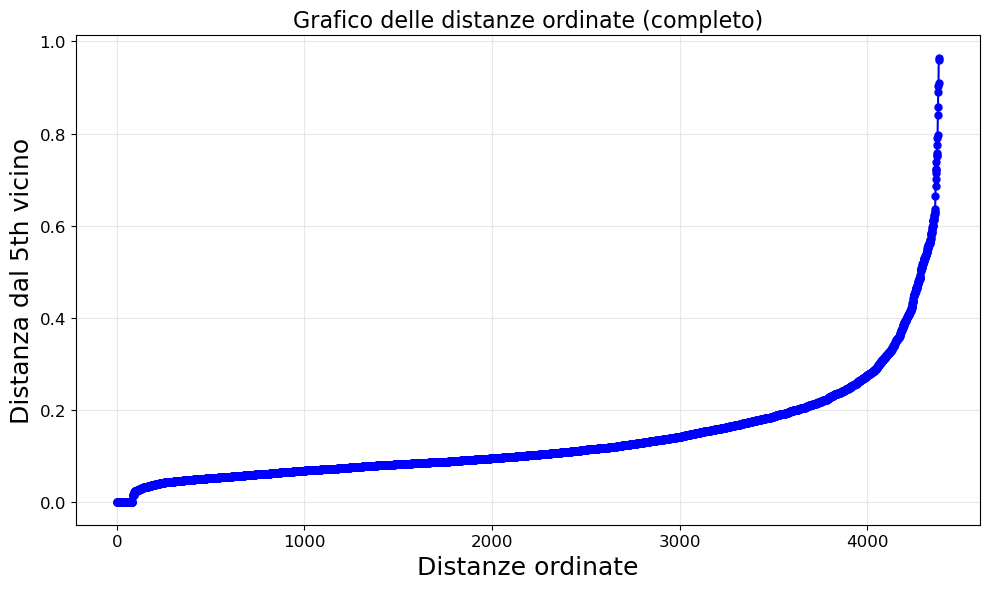

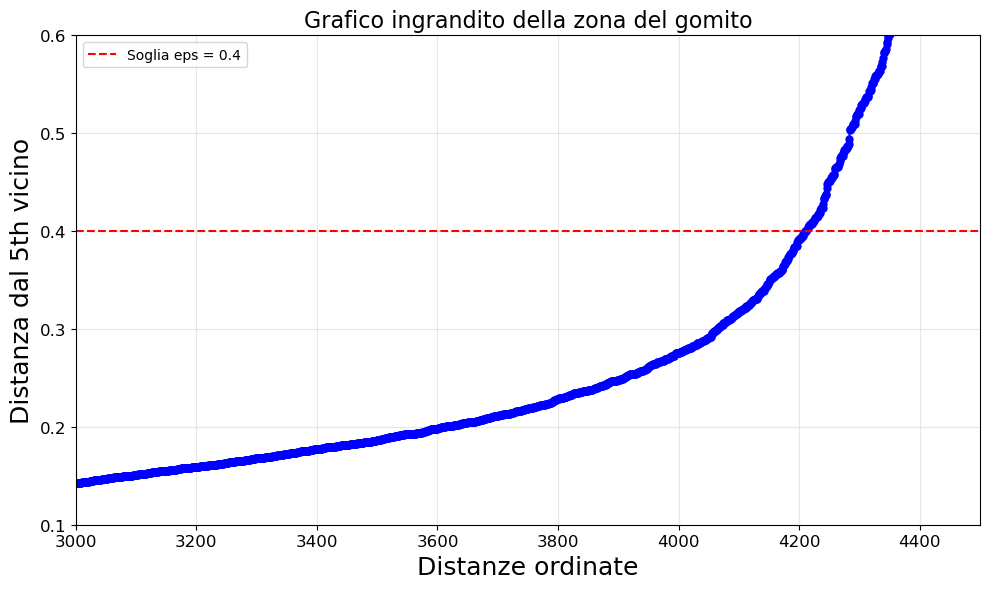

In [177]:
# Plot completo delle distanze ordinate
plt.figure(figsize=(10, 6))
plt.plot(range(0, len(kth_distances)), sorted(kth_distances), color='blue', linestyle='-', marker='o', markersize=5)
plt.ylabel('Distanza dal %sth vicino' % k, fontsize=18)
plt.xlabel('Distanze ordinate', fontsize=18)
plt.tick_params(axis='both', which='major', labelsize=12)
plt.title("Grafico delle distanze ordinate (completo)", fontsize=16)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Plot ingrandito della zona del gomito
plt.figure(figsize=(10, 6))
plt.plot(range(0, len(kth_distances)), sorted(kth_distances), color='blue', linestyle='-', marker='o', markersize=5)
plt.xlim(3000, 4500)  # Limita l'asse X per concentrarti sui primi punti
plt.ylim(0.1, 0.6)  # Limita l'asse Y per concentrarti sulla zona del gomito
plt.ylabel('Distanza dal %sth vicino' % k, fontsize=18)
plt.xlabel('Distanze ordinate', fontsize=18)
plt.tick_params(axis='both', which='major', labelsize=12)
plt.axhline(y=best_eps, color='red', linestyle='--', label=f'Soglia eps = {best_eps}')
plt.title("Grafico ingrandito della zona del gomito", fontsize=16)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [178]:
#Based on the plot, we choose eps = 0.3
dbscan = DBSCAN(eps= best_eps,min_samples= best_ms)
dbscan.fit(X)

,eps,0.4
,min_samples,21
,metric,'euclidean'
,metric_params,None
,algorithm,'auto'
,leaf_size,30
,p,None
,n_jobs,None


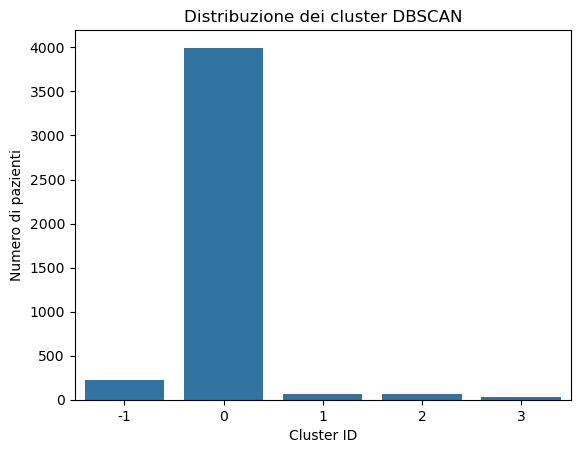

In [179]:
# Aggiungi i cluster assegnati al DataFrame
profile_df['cluster'] = dbscan.labels_

# Ora puoi creare il grafico
sns.countplot(x='cluster', data=profile_df)
plt.title("Distribuzione dei cluster DBSCAN")
plt.xlabel("Cluster ID")
plt.ylabel("Numero di pazienti")
plt.show()

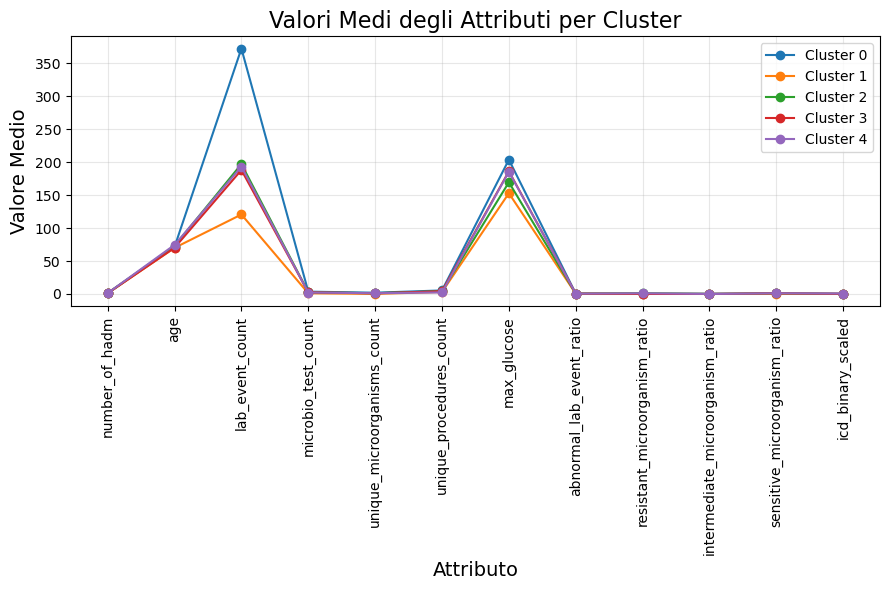

In [180]:
# Aggiungi 1 ai cluster per evitare valori negativi (noise diventa 0)
profile_df["cluster"] = dbscan.labels_ + 1

# Calcola le medie per cluster, escludendo subject_id
numeric_cols_for_plot = [col for col in profile_df.columns if col not in ['subject_id', 'cluster']]
means = profile_df.groupby('cluster')[numeric_cols_for_plot].mean()

# Crea un grafico a linee per ciascun cluster
plt.figure(figsize=(9, 6))
for cluster in means.index:
    plt.plot(means.columns, means.loc[cluster], marker='o', label=f'Cluster {cluster}')

plt.xlabel('Attributo', fontsize=14)
plt.ylabel('Valore Medio', fontsize=14)
plt.title('Valori Medi degli Attributi per Cluster', fontsize=16)
plt.legend()
plt.xticks(rotation=90)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

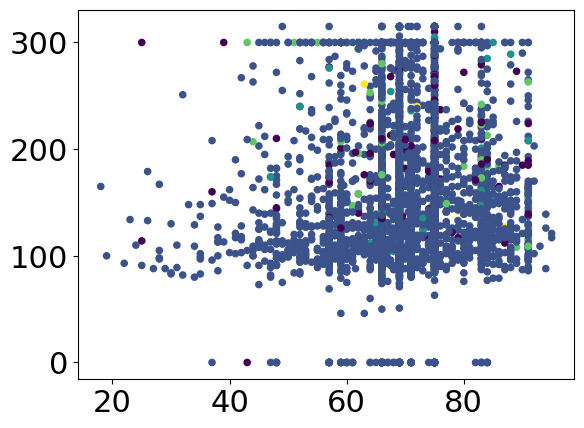

In [181]:


# Ora puoi creare il grafico
plt.scatter(profile_df['age'], profile_df['max_glucose'], c=dbscan.labels_, s=20)
plt.tick_params(axis='both', which='major', labelsize=22)
plt.show()